# Example #2: Simulating an SIS mixer

- This example will simulate a simple SIS mixer.
- The input will consists of 3 signals:
    - a strong local-osciallator (LO) signal at 230 GHz,
    - a weak RF signal at 232 GHz, and
    - an IF output at 2 GHz.
- An arbitrary embedding circuit is included (therefore, harmonic balance is required).
- The response function is generated from an experimental DC I-V curve.
- This simulation will calculate:
    - the pumped I-V curve,
    - the mixer's gain, and
    - the mixer's noise temperature (from a small-signal analysis of the LO alone).

In [1]:
%matplotlib inline

import qmix
import numpy as np
import scipy.constants as sc 
import matplotlib.pyplot as plt

from qmix.mathfn.misc import slope
from qmix.qtcurrent import qtcurrent
from qmix.circuit import EmbeddingCircuit
from qmix.harmonic_balance import harmonic_balance
from qmix.small_signal import (admittance_matrix, noise_matrix, sideband_impedances, conversion_gain,
                               embedding_noise, noise_temperature)

# https://github.com/garrettj403/SciencePlots
import scienceplots
plt.style.use(['science', 'notebook'])

## Define the junction properties
- These are common parameters that describe the electrical properties of SIS junctions. QMix only uses normalized values, so these values will be used to de-normalize whatever voltages, currents and frequencies that QMix calculates.

In [2]:
vgap = 2.7e-3              # gap voltage in [V]
rn   = 13.5                # normal resistance in [ohms]
igap = vgap / rn           # gap current in [A]
fgap = sc.e * vgap / sc.h  # gap frequency in [Hz]

## Define the embedding circuit
- We will load the ``EmbeddingCircuit`` class with all of the information about the embedding circuit. This includes the Thevenin voltage, the Thevenin impedance, and the frequency of each signal that is applied to the junction.
- Note: 
   - All of the circuit properties are normalized: 
      - voltages are normalized to the gap voltage (``vgap``), 
      - resistances to the normal resistance (``rn``), 
      - currents to the gap current (``igap = vgap / rn``), and 
      - frequencies to the gap frequency (``fgap``).
   - This example includes the embedding circuit. Each tone/harmonic requires:
      - the Thevenin voltage (normalized to ``vgap``)
      - the Thevenin impedance (normalized to ``rn``)
      - the frequency (normalized to ``fgap``).
   - The normalized frequency is the same thing as the normalized photon voltage.

In [3]:
# simulation parameters
num_f = 3  # number of tones
num_p = 1  # number of harmonics
num_b = (10, 5, 10)  # Bessel function summation limits

# LO signal
f_lo         = 230e9 / fgap      # frequency (normalized value)
alpha_lo     = 1.2               # junction drive level (normalized value)
impedance_lo = 0.3 - 0.3*1j      # embedding impedance (normalized value)

# RF signal
f_rf         = 232e9 / fgap      # frequency (normalized value)
alpha_rf     = 0.012             # junction drive level (normalized value)
impedance_rf = 0.3 - 0.3*1j      # embedding impedance (normalized value)

# IF signal
f_if         = 2e9 / fgap        # frequency (normalized value)
impedance_if = 1.                # embedding impedance (normalized value)

# build embedding circuit
cct = EmbeddingCircuit(num_f, num_p, fgap=fgap, vgap=vgap, rn=rn)
cct.comment[1][1] = 'LO'
cct.comment[2][1] = 'USB'
cct.comment[3][1] = 'IF'

# photon voltages (same as normalized frequency)
cct.freq[1] = f_lo
cct.freq[2] = f_rf
cct.freq[3] = f_if

# Thevenin voltages
cct.vt[1, 1] = cct.freq[1] * alpha_lo
cct.vt[2, 1] = cct.freq[2] * alpha_rf
cct.vt[3, 1] = 0.

# Thevenin impedances
cct.zt[1, 1] = impedance_lo
cct.zt[2, 1] = impedance_rf
cct.zt[3, 1] = impedance_if

cct.print_info()

Embedding circuit (Tones:3, Harmonics:1)
   f=1, p=1			230.0 GHz x 1		LO
	Thev. voltage:		0.4228 * Vgap
	              		1.2000 * Vph
	Thev. impedance:	0.30-0.30j * Rn
	Avail. power:   	4.02E-08 W
	                	-43.956 dBm
   f=2, p=1			232.0 GHz x 1		USB
	Thev. voltage:		0.0043 * Vgap
	              		0.0120 * Vph
	Thev. impedance:	0.30-0.30j * Rn
	Avail. power:   	4.09E-12 W
	                	-83.881 dBm
   f=3, p=1			2.0 GHz x 1		IF
	Thev. voltage:		0.0000 * Vgap
	              		0.0000 * Vph
	Thev. impedance:	1.00+0.00j * Rn
	Avail. power:   	0.00E+00 W
	                	-inf dBm



## Generate the response function

- Here, the response function is generated from an experimental DC I-V curve.

In [4]:
# Load DC I-V data
dciv_exp_data = np.genfromtxt('example-data/dciv.csv', delimiter=',')
dciv = qmix.exp.DCData(dciv_exp_data)

# Grab response function
resp = dciv.resp


DC I-V data: 

	Vgap:  		  2.72	mV
	fgap:  		656.99	GHz

	Rn:    		 14.22	ohms
	Rsg:   		367.87	ohms
	Q:     		 25.87

	Jc:    		 12.74	kA/cm^2
	Ileak: 		  8.68	uA

	Offset:		  0.10	mV
	       		  9.71	uA

	Vint:  		  0.21	mV



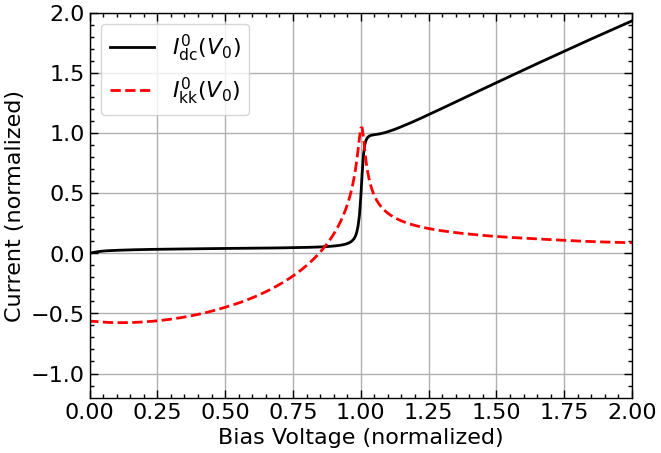

In [5]:
# Plot
fig, ax = plt.subplots(figsize=(7,5))
resp.plot(ax=ax);

## Perform harmonic balance

- Calculate the voltage drop across the junction for each tone/harmonic using harmonic balance.

In [6]:
vj = harmonic_balance(cct, resp, num_b)

Running harmonic balance:
 - 3 tone(s) and 1 harmonic(s)
 - analytic Jacobian
 - max. iterations: 30
Estimated time:
 - time per qtc call:     0.01 s /   0.00 min /  0.00 hrs
 - time per iteration:    0.04 s /   0.00 min /  0.00 hrs
 - max sim time:          1.17 s /   0.02 min /  0.00 hrs
Error after 0 iteration(s):
	f:1, p:1,   med. rel. error:     0.265,   max. rel. error:     1.069,     0.0 % complete
	f:2, p:1,   med. rel. error:     0.202,   max. rel. error:     0.811,     0.0 % complete
	f:3, p:1,   med. rel. error: 99999.999,   max. rel. error: 99999.999,     0.0 % complete
Applying correction
Error after 1 iteration(s):
	f:1, p:1,   med. rel. error:     0.003,   max. rel. error:     0.156,    33.3 % complete
	f:2, p:1,   med. rel. error:     0.014,   max. rel. error:     0.271,    14.9 % complete
	f:3, p:1,   med. rel. error:     0.075,   max. rel. error:    20.842,     0.0 % complete
Reusing Jacobian from previous iteration
Applying correction
Error after 2 iteration(s):
	f:1

## Calculate tunnelling currents
- ``idc`` is the DC tunneling current
- ``ilo`` is the AC tunneling current at the LO frequency
- ``iif`` is the AC tunneling current at the IF frequency

In [7]:
freq_list = [0., f_lo, f_if]
idc, ilo, iif = qtcurrent(vj, cct, resp, freq_list, num_b=num_b)

Calculating tunneling current...
 - 3 tone(s)
 - 1 harmonic(s)
 - method: direct
Done.
Time: 0.0278 s



### Calculate mixer gain

In [8]:
# Available power from upper sideband (USB)
pusb = cct.available_power(f=2)

# Power delivered to load
rload = cct.zt[3,1].real * rn
pload = 0.5 * np.abs(iif * igap)**2 * rload

# Gain
gain = pload / pusb

### Calculate noise temperature

- The multi-tone simulation above doesn't include the shot noise of the junction. The noise is calculated with a small-signal (Tucker) analysis instead (see the Theory section of the documentation): the LO alone is simulated with harmonic balance, and the RF and IF signals are then treated as small signals.
- ``admittance_matrix`` gives the conversion admittance matrix between the sidebands ``m * f_lo + f_if`` (here, m = -1, 0, 1: the LSB, the IF and the USB), and ``noise_matrix`` the correlation matrix of the junction's noise currents at these sidebands (shot noise, including its thermal and quantum limits), at the physical temperature of the junction.
- ``sideband_impedances`` collects the embedding impedances at the IF, USB and LSB. The LSB (228 GHz) isn't one of the tones of the simulation above, so its voltage is zero there, i.e., it is shorted. The same is done here, so that the two calculations describe the same mixer: the small-signal gain should agree with the gain from above (up to the small error from the finite RF power).
- ``embedding_noise`` adds the thermal noise of the embedding impedances (Callen-Welton), and ``noise_temperature`` gives the single-sideband (SSB) noise temperature for a USB input (without the noise of the source and of the IF load).

In [9]:
temp = 4.2  # physical temperature of the junction and the embedding circuit, in [K]

# LO alone (same Thevenin circuit as above)
cct_lo = EmbeddingCircuit(1, 1, fgap=fgap, vgap=vgap, rn=rn)
cct_lo.freq[1] = f_lo
cct_lo.vt[1, 1] = cct.vt[1, 1]
cct_lo.zt[1, 1] = cct.zt[1, 1]
vj_lo = harmonic_balance(cct_lo, resp, num_b=15, verbose=False)

# Admittance and noise matrices of the pumped junction (sidebands m = -1, 0, 1)
y = admittance_matrix(vj_lo, cct_lo, resp, f_if, num_b=15)
h = noise_matrix(vj_lo, cct_lo, resp, f_if, temp, vgap)

# Embedding impedances at the IF, USB and LSB (LSB shorted, as in the multi-tone simulation)
zt = sideband_impedances(impedance_if, impedance_rf, 0.)
v_noise = embedding_noise(zt, temp, f_lo, f_if, vgap)

# Gain (USB -> IF) and SSB noise temperature (USB input)
gain_ss = conversion_gain(y, zt, 1)
tn_ssb = noise_temperature(y, h, zt, vgap, 1, v_noise=v_noise)

# Best bias point
idx = np.argmax(gain_ss)
print("Best bias:          {:.2f} mV".format(cct.vb[idx] * vgap / sc.milli))
print("Gain:               {:.1f} % (multi-tone: {:.1f} %)".format(gain_ss[idx] * 100, gain[idx] * 100))
print("SSB noise temp.:    {:.1f} K".format(tn_ssb[idx]))
print("Quantum limit h f / k at the USB: {:.1f} K".format(sc.h * f_rf * fgap / sc.k))

Best bias:          2.27 mV
Gain:               32.6 % (multi-tone: 32.6 %)
SSB noise temp.:    17.0 K
Quantum limit h f / k at the USB: 11.1 K


## Plot Results

In [10]:
# Conversion: normalized -> de-normalized
vmv = vgap / sc.milli 
iua = igap / sc.micro

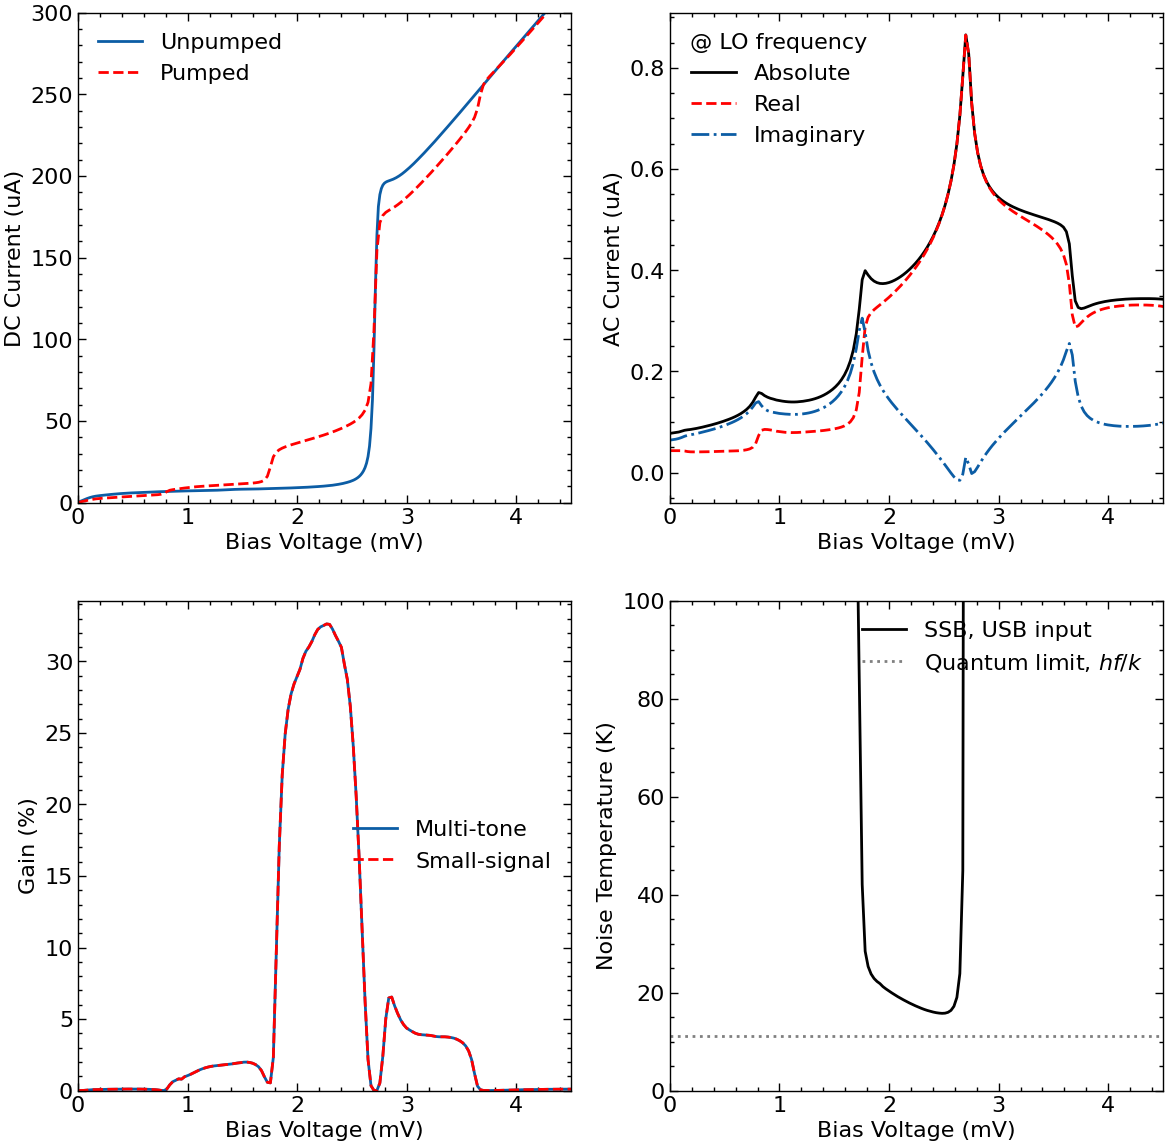

In [11]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14,14))

# Plot I-V curves
ax1.plot(resp.voltage*vmv, resp.current*iua, label='Unpumped')
ax1.plot(cct.vb*vmv, idc.real*iua, 'r--', label='Pumped')
ax1.set(xlim=(0,4.5), xlabel='Bias Voltage (mV)')
ax1.set(ylim=(0,300), ylabel='DC Current (uA)')
ax1.legend(frameon=False)

# Plot AC currents at LO frequency
ax2.plot(cct.vb*vmv, np.abs(ilo), 'k', label='Absolute')
ax2.plot(cct.vb*vmv, ilo.real, 'r--', label='Real')
ax2.plot(cct.vb*vmv, ilo.imag, ls='-.', label='Imaginary')
ax2.set(xlim=(0,4.5), xlabel='Bias Voltage (mV)')
ax2.set(ylabel='AC Current (uA)')
ax2.legend(frameon=False, loc=2, title="@ LO frequency")

# Plot gain of SIS junction (multi-tone simulation and small-signal analysis)
ax3.plot(cct.vb*vmv, gain*100, label='Multi-tone')
ax3.plot(cct.vb*vmv, gain_ss*100, 'r--', label='Small-signal')
ax3.set(xlim=(0,4.5), xlabel='Bias Voltage (mV)')
ax3.set(ylabel='Gain (%)')
ax3.set_ylim(bottom=0)
ax3.legend(frameon=False)

# Plot SSB noise temperature (small-signal analysis)
ax4.plot(cct.vb*vmv, tn_ssb, 'k', label='SSB, USB input')
ax4.axhline(sc.h * f_rf * fgap / sc.k, c='gray', ls=':', label='Quantum limit, $hf/k$')
ax4.set(xlim=(0,4.5), xlabel='Bias Voltage (mV)')
ax4.set(ylim=(0,100), ylabel='Noise Temperature (K)')
ax4.legend(frameon=False)

fig.savefig('multi-tone-results.png', dpi=500, bbox_inches='tight');